In [1]:
# Check whether the downloaded master table is available
from pathlib import Path

master_path = Path("/Users/lvchris/Downloads/master_daily.csv")

print("File exists:", master_path.exists())
print("File path:", master_path)

File exists: True
File path: /Users/lvchris/Downloads/master_daily.csv


In [4]:
# Load the master table and prepare it for preliminary analysis
import pandas as pd

calendar = pd.read_csv(master_path)

# Standardise the date column name before analysis
calendar = calendar.rename(columns={"Date": "date"})

# Convert date and outcome columns to usable formats
calendar["date"] = pd.to_datetime(calendar["date"])
calendar["Net_Departure"] = pd.to_numeric(
    calendar["Net_Departure"],
    errors="coerce",
)

# Exclude X8 from the preliminary analysis
calendar = calendar.drop(
    columns=["is_hk_school_short_break"],
    errors="ignore",
)

print("Number of rows:", len(calendar))
print(
    "Date range:",
    calendar["date"].min().date(),
    "to",
    calendar["date"].max().date(),
)
print(
    "Does X8 still exist?",
    "is_hk_school_short_break" in calendar.columns,
)

print("\nFirst five rows:")
print(
    calendar[
        [
            "date",
            "Net_Departure",
            "is_weekend",
            "is_hk_public_holiday",
            "is_hk_school_long_break",
        ]
    ].head()
)

Number of rows: 1364
Date range: 2023-02-06 to 2026-10-31
Does X8 still exist? False

First five rows:
        date  Net_Departure  is_weekend  is_hk_public_holiday  \
0 2023-02-06           5617           0                     0   
1 2023-02-07           -891           0                     0   
2 2023-02-08            -61           0                     0   
3 2023-02-09           5081           0                     0   
4 2023-02-10          36305           0                     0   

   is_hk_school_long_break  
0                        0  
1                        0  
2                        0  
3                        0  
4                        0  


In [6]:
# H2: Compare average northbound passenger counts across calendar indicators
outcome = "Northbound_Passengers"

h2_features = {
    "Weekend": "is_weekend",
    "Hong Kong public holiday": "is_hk_public_holiday",
    "Long weekend": "is_long_weekend",
}

h2_rows = []

for feature_name, column_name in h2_features.items():
    grouped = (
        calendar.groupby(column_name)[outcome]
        .agg(["count", "mean", "median", "std"])
    )

    h2_rows.append(
        {
            "Calendar feature": feature_name,
            "Days without feature": grouped.loc[0, "count"],
            "Days with feature": grouped.loc[1, "count"],
            "Mean without feature": grouped.loc[0, "mean"],
            "Mean with feature": grouped.loc[1, "mean"],
            "Difference (with - without)": (
                grouped.loc[1, "mean"] - grouped.loc[0, "mean"]
            ),
            "Median with feature": grouped.loc[1, "median"],
        }
    )

h2_summary_passengers = pd.DataFrame(h2_rows)

print("H2 preliminary comparison using Northbound_Passengers:")
display(h2_summary_passengers.round(2))

H2 preliminary comparison using Northbound_Passengers:


,Calendar feature,Days without feature,Days with feature,Mean without feature,Mean with feature,Difference (with - without),Median with feature
0,Weekend,975,389,231194.23,305467.94,74273.71,296476.0
1,Hong Kong public holiday,1302,62,249720.51,308149.89,58429.37,289641.0
2,Long weekend,1285,79,247901.52,325163.86,77262.34,312926.0


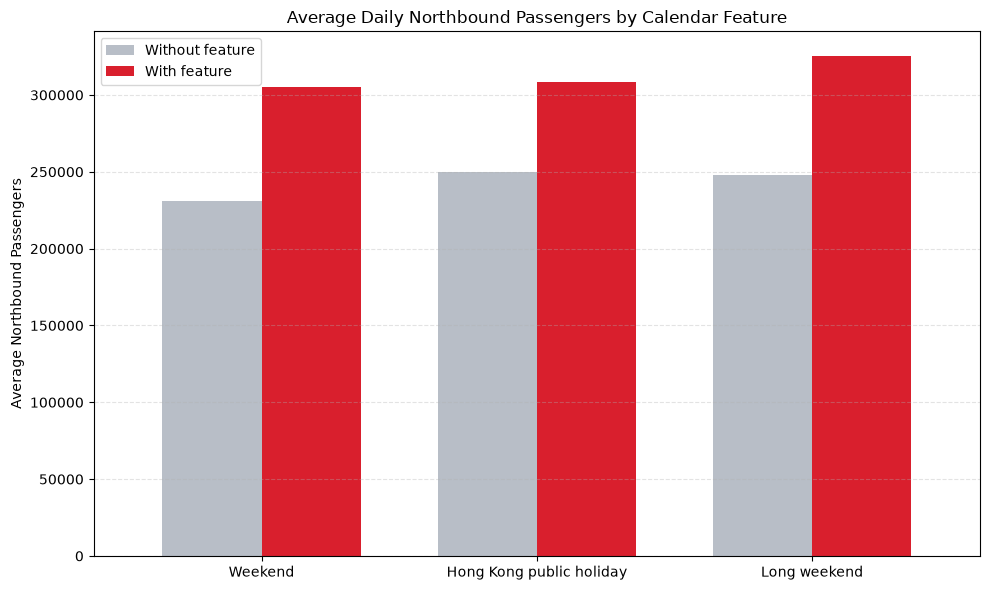

In [7]:
# H2 chart: average northbound passengers with and without each calendar feature
import matplotlib.pyplot as plt

h2_plot = h2_summary_passengers.set_index("Calendar feature")[
    ["Mean without feature", "Mean with feature"]
]

ax = h2_plot.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#B8BEC7", "#D91F2D"],
    width=0.72,
)

ax.set_title("Average Daily Northbound Passengers by Calendar Feature")
ax.set_ylabel("Average Northbound Passengers")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Without feature", "With feature"])
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import ttest_ind

h2_test_rows = []

for feature_name, column_name in h2_features.items():
    without_feature = calendar.loc[
        calendar[column_name] == 0,
        outcome,
    ].dropna()

    with_feature = calendar.loc[
        calendar[column_name] == 1,
        outcome,
    ].dropna()

    t_statistic, p_value = ttest_ind(
        with_feature,
        without_feature,
        equal_var=False,
    )

    h2_test_rows.append(
        {
            "Calendar feature": feature_name,
            "Mean difference": (
                with_feature.mean() - without_feature.mean()
            ),
            "t statistic": t_statistic,
            "p value": p_value,
            "Conclusion": (
                "Statistically significant"
                if p_value < 0.05
                else "Not statistically significant"
            ),
        }
    )

h2_tests = pd.DataFrame(h2_test_rows)

h2_tests_rounded = h2_tests.copy()

h2_tests_rounded["Mean difference"] = (
    h2_tests_rounded["Mean difference"].round(2)
)
h2_tests_rounded["t statistic"] = (
    h2_tests_rounded["t statistic"].round(2)
)
h2_tests_rounded["p value"] = (
    h2_tests_rounded["p value"].apply(lambda x: f"{x:.4g}")
)

print(h2_tests_rounded.to_string(index=False))

        Calendar feature  Mean difference  t statistic   p value                Conclusion
                 Weekend         74273.71        14.53  5.09e-41 Statistically significant
Hong Kong public holiday         58429.37         3.60 0.0006315 Statistically significant
            Long weekend         77262.34         5.31  9.38e-07 Statistically significant


## H2: Calendar Effects on Northbound Passenger Volume

Preliminary descriptive and Welch’s t-test results support H2. Average daily northbound passenger volume was significantly higher on weekends, Hong Kong public holidays, and long weekends than on other days.

The largest uplift was observed during long weekends, with an average increase of 77,262 passengers per day. These results describe associations only; the final multivariable analysis will control for overlapping calendar, weather, policy, and market factors.

In [11]:
# H3: Hong Kong school long-break days and northbound passengers
h3_column = "is_hk_school_long_break"

h3_grouped = (
    calendar.groupby(h3_column)["Northbound_Passengers"]
    .agg(["count", "mean", "median", "std"])
)

h3_difference = (
    h3_grouped.loc[1, "mean"] - h3_grouped.loc[0, "mean"]
)

print("H3: Hong Kong school long-break comparison")
print("Days without long break:", h3_grouped.loc[0, "count"])
print("Days with long break:", h3_grouped.loc[1, "count"])
print("Mean without long break:", round(h3_grouped.loc[0, "mean"], 2))
print("Mean with long break:", round(h3_grouped.loc[1, "mean"], 2))
print("Difference (with - without):", round(h3_difference, 2))
print("Median with long break:", round(h3_grouped.loc[1, "median"], 2))

H3: Hong Kong school long-break comparison
Days without long break: 1058
Days with long break: 306
Mean without long break: 247476.48
Mean with long break: 269317.92
Difference (with - without): 21841.44
Median with long break: 257461.5


In [12]:
# H3 statistical test: school long-break days vs other days
from scipy.stats import ttest_ind

h3_without = calendar.loc[
    calendar["is_hk_school_long_break"] == 0,
    "Northbound_Passengers",
].dropna()

h3_with = calendar.loc[
    calendar["is_hk_school_long_break"] == 1,
    "Northbound_Passengers",
].dropna()

h3_t_statistic, h3_p_value = ttest_ind(
    h3_with,
    h3_without,
    equal_var=False,
)

print("H3: Hong Kong school long-break test")
print("Mean difference:", round(h3_with.mean() - h3_without.mean(), 2))
print("t statistic:", round(h3_t_statistic, 2))
print("p value:", f"{h3_p_value:.4g}")

if h3_p_value < 0.05:
    print("Conclusion: Statistically significant")
else:
    print("Conclusion: Not statistically significant")

H3: Hong Kong school long-break test
Mean difference: 21841.44
t statistic: 3.82
p value: 0.0001548
Conclusion: Statistically significant


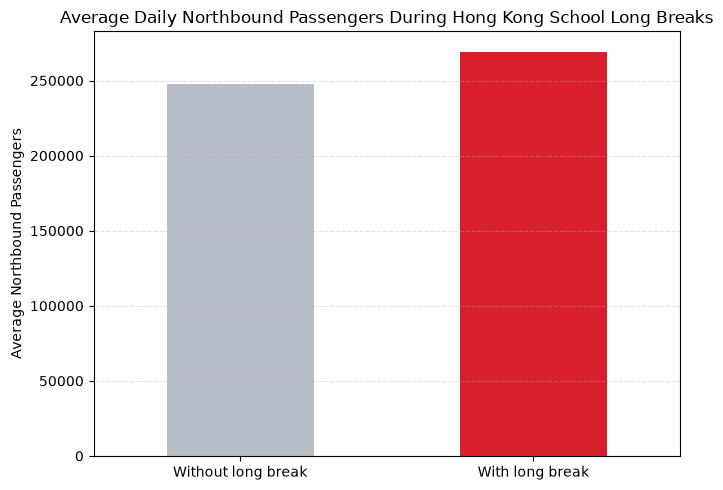

In [13]:
# H3 chart: average northbound passengers during school long breaks
h3_plot = pd.DataFrame(
    {
        "Period": ["Without long break", "With long break"],
        "Average passengers": [
            h3_without.mean(),
            h3_with.mean(),
        ],
    }
)

ax = h3_plot.plot(
    x="Period",
    y="Average passengers",
    kind="bar",
    legend=False,
    figsize=(7, 5),
    color=["#B8BEC7", "#D91F2D"],
)

ax.set_title("Average Daily Northbound Passengers During Hong Kong School Long Breaks")
ax.set_ylabel("Average Northbound Passengers")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

## H3: Hong Kong School Long Breaks

Preliminary results support H3. Average daily northbound passenger volume was 21,841 passengers higher during Hong Kong school long-break days than during other days.

The difference was statistically significant (Welch’s t-test, p = 0.0001548). This result indicates an association; it will be reassessed in the final multivariable analysis.

In [14]:
# H4: Mainland holidays and Shenzhen school breaks
h4_features = {
    "Mainland public holiday": "is_mainland_holiday",
    "Shenzhen winter break": "is_sz_winter_break",
    "Shenzhen summer break": "is_sz_summer_break",
}

h4_rows = []

for feature_name, column_name in h4_features.items():
    grouped = calendar.groupby(column_name)["Northbound_Passengers"].agg(
        ["count", "mean", "median"]
    )

    h4_rows.append(
        {
            "Calendar feature": feature_name,
            "Days without feature": grouped.loc[0, "count"],
            "Days with feature": grouped.loc[1, "count"],
            "Mean without feature": round(grouped.loc[0, "mean"], 2),
            "Mean with feature": round(grouped.loc[1, "mean"], 2),
            "Difference (with - without)": round(
                grouped.loc[1, "mean"] - grouped.loc[0, "mean"],
                2,
            ),
        }
    )

h4_summary = pd.DataFrame(h4_rows)
print(h4_summary.to_string(index=False))

       Calendar feature  Days without feature  Days with feature  Mean without feature  Mean with feature  Difference (with - without)
Mainland public holiday                  1256                108             252094.78          255651.46                      3556.68
  Shenzhen winter break                  1272                 92             251661.04          262266.96                     10605.92
  Shenzhen summer break                  1164                200             251802.16          255718.43                      3916.27


In [15]:
# H4 statistical tests
h4_test_rows = []

for feature_name, column_name in h4_features.items():
    without_feature = calendar.loc[
        calendar[column_name] == 0,
        "Northbound_Passengers",
    ].dropna()

    with_feature = calendar.loc[
        calendar[column_name] == 1,
        "Northbound_Passengers",
    ].dropna()

    t_statistic, p_value = ttest_ind(
        with_feature,
        without_feature,
        equal_var=False,
    )

    h4_test_rows.append(
        {
            "Calendar feature": feature_name,
            "Mean difference": round(
                with_feature.mean() - without_feature.mean(),
                2,
            ),
            "t statistic": round(t_statistic, 2),
            "p value": f"{p_value:.4g}",
            "Conclusion": (
                "Statistically significant"
                if p_value < 0.05
                else "Not statistically significant"
            ),
        }
    )

h4_tests = pd.DataFrame(h4_test_rows)
print(h4_tests.to_string(index=False))

       Calendar feature  Mean difference  t statistic p value                    Conclusion
Mainland public holiday          3556.68         0.44  0.6605 Not statistically significant
  Shenzhen winter break         10605.92         1.44  0.1524 Not statistically significant
  Shenzhen summer break          3916.27         0.66  0.5089 Not statistically significant


## H4: Mainland Holidays and Shenzhen School Breaks

Preliminary tests did not find statistically significant differences in average daily northbound passenger volume during Mainland public holidays, Shenzhen winter breaks, or Shenzhen summer breaks (all p-values > 0.05).

Therefore, H4 is not supported by the preliminary univariate analysis. These variables may still be retained as control variables and reassessed in the final multivariable model.